## 📌 1. Configuração Inicial

In [13]:
modelo = "qwen2.5-coder:32b"
platform = "npm"
extension_1 = "E2_v5"
extension_2 = "E2_v7"

import pandas as pd
from pathlib import Path
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, multilabel_confusion_matrix

def load_results(extension):
    file_path = Path(f"../data/output/{modelo}/{platform}/{extension}.json")
    with open(file_path, "r") as f:
        data = json.load(f)
    return pd.DataFrame(data["results"])

df1 = load_results(extension_1)
df2 = load_results(extension_2)


### 📌 2. Gerar relatório detalhado


In [14]:
classes = ['feat', 'fix', 'docs', 'style', 'refactor', 'perf',
           'test', 'build', 'ci', 'chore', 'others']

def generate_report(df):
    report = classification_report(
        df['label'],
        df['type'],
        labels=classes,
        output_dict=True,
        zero_division=0
    )
    df_report = pd.DataFrame(report).transpose().loc[classes]
    df_report["support"] = df_report["support"].astype(int)
    df_report.reset_index(inplace=True)
    df_report.rename(columns={"index": "class"}, inplace=True)

    total = df_report["support"].sum()
    total_df = pd.DataFrame([{
        "class": "Total",
        "precision": float("nan"),
        "recall": float("nan"),
        "f1-score": float("nan"),
        "support": total
    }])

    df_report = pd.concat([df_report, total_df], ignore_index=True)

    for col in ["precision", "recall", "f1-score"]:
        df_report[col] = df_report[col].apply(lambda x: "-" if pd.isna(x) else f"{x:.2f}")

    return df_report

report_1 = generate_report(df1)
report_2 = generate_report(df2)

display(report_1.style.set_caption(f"Extensão: {extension_1}"))
display(report_2.style.set_caption(f"Extensão: {extension_2}"))


,class,precision,recall,f1-score,support
0,feat,0.22,0.62,0.33,16
1,fix,0.48,0.84,0.61,51
2,docs,0.98,0.44,0.61,93
3,style,0.00,0.00,0.00,0
4,refactor,0.64,0.54,0.59,111
5,perf,0.10,1.00,0.18,1
6,test,0.56,0.62,0.59,8
7,build,0.85,0.66,0.74,50
8,ci,0.00,0.00,0.00,12
9,chore,0.00,0.00,0.00,0


,class,precision,recall,f1-score,support
0,feat,0.27,0.56,0.37,16
1,fix,0.48,0.84,0.61,51
2,docs,0.98,0.51,0.67,93
3,style,0.00,0.00,0.00,0
4,refactor,0.64,0.65,0.65,111
5,perf,0.00,0.00,0.00,1
6,test,0.56,0.62,0.59,8
7,build,0.91,0.64,0.75,50
8,ci,0.33,0.08,0.13,12
9,chore,0.00,0.00,0.00,0


### Total por classe

In [15]:
def resultado_acertos(df):
    df["acerto"] = df["label"] == df["type"]
    support = df["label"].value_counts().rename("total")
    acertos = df[df["acerto"]]["label"].value_counts().rename("acertos")
    resultado = pd.concat([support, acertos], axis=1).fillna(0)
    resultado["erros"] = resultado["total"] - resultado["acertos"]
    return resultado.astype(int)[["acertos", "erros", "total"]].sort_values(by="total", ascending=False)

resultado_1 = resultado_acertos(df1)
resultado_2 = resultado_acertos(df2)

display(resultado_1.style.set_caption(f"Extensão: {extension_1}"))
display(resultado_2.style.set_caption(f"Extensão: {extension_2}"))


,acertos,erros,total
label,,,
refactor,60,51,111
docs,41,52,93
fix,43,8,51
build,33,17,50
feat,10,6,16
others,4,10,14
ci,0,12,12
test,5,3,8
perf,1,0,1


,acertos,erros,total
label,,,
refactor,72,39,111
docs,47,46,93
fix,43,8,51
build,32,18,50
feat,9,7,16
others,1,13,14
ci,1,11,12
test,5,3,8
perf,0,1,1


### Confusao

In [16]:
def gerar_confusao(df):
    labels = sorted(df["label"].unique())
    mcm = multilabel_confusion_matrix(df["label"], df["type"], labels=labels)

    confusion_data = []
    for label, matrix in zip(labels, mcm):
        tn, fp, fn, tp = matrix.ravel()
        confusion_data.append({
            "classe": label,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": tn
        })

    return pd.DataFrame(confusion_data).set_index("classe").sort_values(by="TP", ascending=False)

confusion_1 = gerar_confusao(df1)
confusion_2 = gerar_confusao(df2)

display(confusion_1.style.set_caption(f"Extensão: {extension_1}"))
display(confusion_2.style.set_caption(f"Extensão: {extension_2}"))


,TP,FP,FN,TN
classe,,,,
refactor,60,34,51,211
fix,43,46,8,259
docs,41,1,52,262
build,33,6,17,300
feat,10,35,6,305
test,5,4,3,344
others,4,0,10,342
perf,1,9,0,346
ci,0,0,12,344


,TP,FP,FN,TN
classe,,,,
refactor,72,40,39,205
docs,47,1,46,262
fix,43,46,8,259
build,32,3,18,303
feat,9,24,7,316
test,5,4,3,344
ci,1,2,11,342
others,1,0,13,342
perf,0,0,1,355


### 📌 Relatório de Classificação


In [17]:
def resumo_classificacao(df, nome):
    print(f"===== {nome} =====")
    print(classification_report(df['label'], df['type'], labels=classes, zero_division=0))
    print(f"Acurácia: {accuracy_score(df['label'], df['type']):.2%}\n")

resumo_classificacao(df1, f"Extensão: {extension_1}")
resumo_classificacao(df2, f"Extensão: {extension_2}")


===== Extensão: E2_v5 =====
              precision    recall  f1-score   support

        feat       0.22      0.62      0.33        16
         fix       0.48      0.84      0.61        51
        docs       0.98      0.44      0.61        93
       style       0.00      0.00      0.00         0
    refactor       0.64      0.54      0.59       111
        perf       0.10      1.00      0.18         1
        test       0.56      0.62      0.59         8
       build       0.85      0.66      0.74        50
          ci       0.00      0.00      0.00        12
       chore       0.00      0.00      0.00         0
      others       1.00      0.29      0.44        14

    accuracy                           0.55       356
   macro avg       0.44      0.46      0.37       356
weighted avg       0.70      0.55      0.58       356

Acurácia: 55.34%

===== Extensão: E2_v7 =====
              precision    recall  f1-score   support

        feat       0.27      0.56      0.37        16
    

### Matriz de Confusão


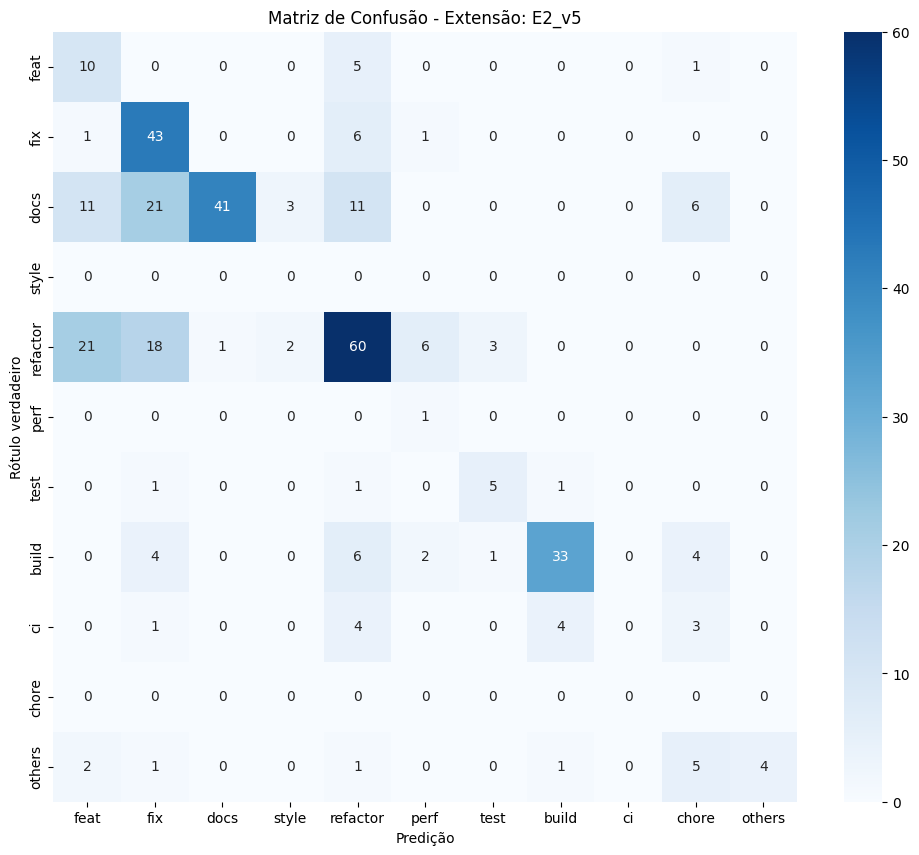

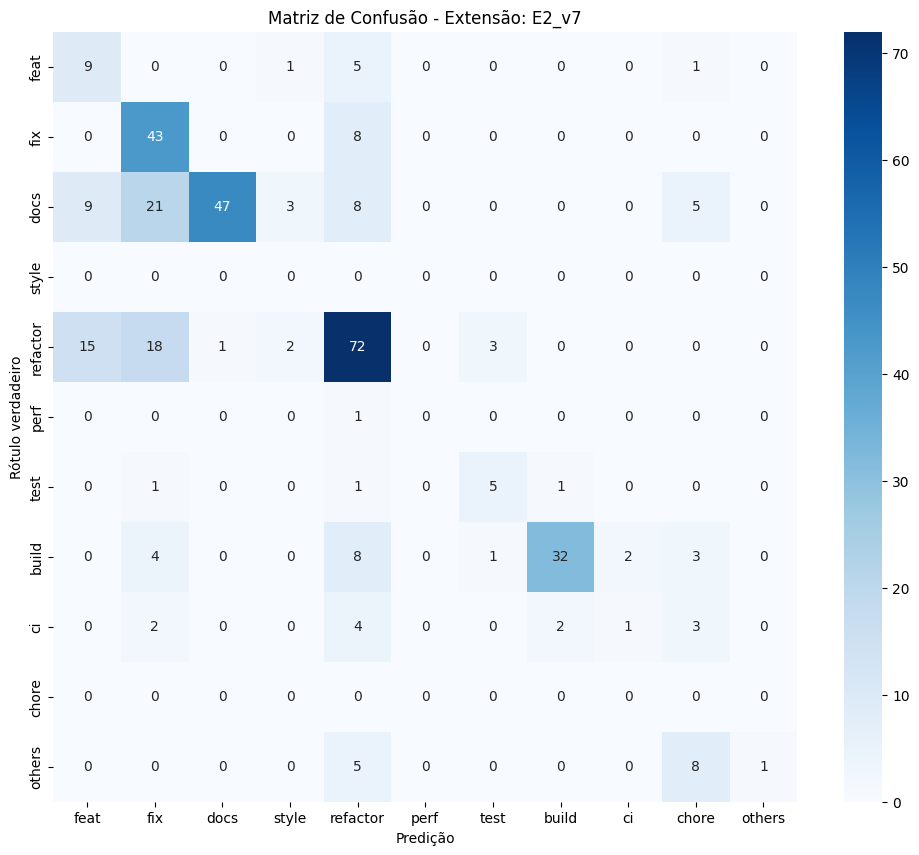

In [18]:
def plot_cm(df, title):
    cm = confusion_matrix(df['label'], df['type'], labels=classes)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes)
    plt.xlabel("Predição")
    plt.ylabel("Rótulo verdadeiro")
    plt.title(title)
    plt.show()

plot_cm(df1, f"Matriz de Confusão - Extensão: {extension_1}")
plot_cm(df2, f"Matriz de Confusão - Extensão: {extension_2}")


### Quebras de Compatibilidade

In [11]:
def breaking_summary(df, nome):
    df_breaking = df[df['breaking_change'] == True]
    total = len(df_breaking)
    correct = df_breaking['breaking_correct'].sum()
    incorrect = total - correct
    taxa_acerto = (correct / total) * 100 if total > 0 else 0
    taxa_erro = 100 - taxa_acerto

    resumo = pd.DataFrame([{
        "Extensão": nome,
        "Total Breaking Changes": total,
        "Acertos": correct,
        "Erros": incorrect,
        "Taxa de Acerto (%)": f"{taxa_acerto:.2f}%",
        "Taxa de Erro (%)": f"{taxa_erro:.2f}%"
    }])
    return resumo

display(breaking_summary(df1, extension_1))
display(breaking_summary(df2, extension_2))


,Extensão,Total Breaking Changes,Acertos,Erros,Taxa de Acerto (%),Taxa de Erro (%)
0,E2_v5,31,4,27,12.90%,87.10%


,Extensão,Total Breaking Changes,Acertos,Erros,Taxa de Acerto (%),Taxa de Erro (%)
0,E2_v6,26,3,23,11.54%,88.46%


### Quebras de Compatibilidade 2

In [12]:
def calc_breaking_metrics(df, nome):
    is_breaking = df['breaking_change'] == True
    predicted_breaking = df['type'] == 'breaking'

    TP = ((is_breaking) & (df['breaking_correct'] == True)).sum()
    FN = ((is_breaking) & (df['breaking_correct'] == False)).sum()
    FP = ((~is_breaking) & (predicted_breaking)).sum()
    TN = ((~is_breaking) & (~predicted_breaking)).sum()

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    return pd.DataFrame([{
        "Extensão": nome,
        "TP": TP, "FP": FP, "FN": FN, "TN": TN,
        "Precisão": f"{precision:.2f}",
        "Recall": f"{recall:.2f}",
        "F1-Score": f"{f1:.2f}"
    }])

display(calc_breaking_metrics(df1, extension_1))
display(calc_breaking_metrics(df2, extension_2))


,Extensão,TP,FP,FN,TN,Precisão,Recall,F1-Score
0,E2_v5,4,0,27,325,1.00,0.13,0.23


,Extensão,TP,FP,FN,TN,Precisão,Recall,F1-Score
0,E2_v6,3,0,23,330,1.00,0.12,0.21
